To connect the drive to notebook for permanent storage.


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


importing libraries and uploading data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Diabetes-Prediction"
)

DATA_PATH = (
    PROJECT_DIR
    / "data"
    / "project_data.xlsx"
)

df = pd.read_excel(DATA_PATH)

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())

Dataset loaded successfully!
Number of rows and columns: (20000, 15)


,Gender,Age,Physical Activity,Smoking Status,Alcohol Intake,Glucose,Blood Pressure,Skin Thickness,Insulin,BMI,Cholesterol,Diabetes Pedigree Function,Family History,Hypertension,Outcome
0,Male,63,Moderate,Former,NaN,103,40,7,41,28.196216,167,1.393,Yes,Yes,Diabetic
1,Female,51,Moderate,Never,Regular,104,59,21,51,30.438114,209,0.815,No,No,Diabetic
2,Female,74,Moderate,Current,NaN,128,70,18,199,38.700428,170,0.244,No,No,Diabetic
3,Male,78,Low,Never,Occasional,148,72,15,110,44.861600,170,0.336,No,No,Diabetic
4,Male,32,High,Never,NaN,102,55,18,49,21.591572,211,1.146,Yes,No,Non-diabetic


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nFirst five rows:")
display(df.head())

print("\nLast five rows:")
display(df.tail())

Column names:
['Gender', 'Age', 'Physical Activity', 'Smoking Status', 'Alcohol Intake', 'Glucose', 'Blood Pressure', 'Skin Thickness', 'Insulin', 'BMI', 'Cholesterol', 'Diabetes Pedigree Function', 'Family History', 'Hypertension', 'Outcome']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Gender                      20000 non-null  object 
 1   Age                         20000 non-null  int64  
 2   Physical Activity           20000 non-null  object 
 3   Smoking Status              20000 non-null  object 
 4   Alcohol Intake              10075 non-null  object 
 5   Glucose                     20000 non-null  int64  
 6   Blood Pressure              20000 non-null  int64  
 7   Skin Thickness              20000 non-null  int64  
 8   Insulin                     20000 non-null  int64 

,Gender,Age,Physical Activity,Smoking Status,Alcohol Intake,Glucose,Blood Pressure,Skin Thickness,Insulin,BMI,Cholesterol,Diabetes Pedigree Function,Family History,Hypertension,Outcome
0,Male,63,Moderate,Former,NaN,103,40,7,41,28.196216,167,1.393,Yes,Yes,Diabetic
1,Female,51,Moderate,Never,Regular,104,59,21,51,30.438114,209,0.815,No,No,Diabetic
2,Female,74,Moderate,Current,NaN,128,70,18,199,38.700428,170,0.244,No,No,Diabetic
3,Male,78,Low,Never,Occasional,148,72,15,110,44.861600,170,0.336,No,No,Diabetic
4,Male,32,High,Never,NaN,102,55,18,49,21.591572,211,1.146,Yes,No,Non-diabetic



Last five rows:


,Gender,Age,Physical Activity,Smoking Status,Alcohol Intake,Glucose,Blood Pressure,Skin Thickness,Insulin,BMI,Cholesterol,Diabetes Pedigree Function,Family History,Hypertension,Outcome
19995,Male,56,Moderate,Former,NaN,156,69,33,134,31.303926,257,0.112,No,No,Diabetic
19996,Male,67,Moderate,Current,NaN,117,79,15,67,38.402759,175,1.443,No,No,Diabetic
19997,Female,66,Moderate,Never,Regular,168,40,30,161,38.260875,193,2.238,No,No,Diabetic
19998,Female,68,Moderate,Never,NaN,130,63,27,105,35.598121,170,1.522,Yes,Yes,Diabetic
19999,Male,25,Low,Current,Regular,122,60,7,27,39.384417,200,0.303,No,No,Diabetic


In [4]:
numerical_cols = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical columns:", numerical_cols)
print("Categorical columns:", categorical_cols)

Numerical columns: ['Age', 'Glucose', 'Blood Pressure', 'Skin Thickness', 'Insulin', 'BMI', 'Cholesterol', 'Diabetes Pedigree Function']
Categorical columns: ['Gender', 'Physical Activity', 'Smoking Status', 'Alcohol Intake', 'Family History', 'Hypertension', 'Outcome']


In [5]:
missing_count = df.isnull().sum()

missing_percent = (
    df.isnull().sum() / len(df)
) * 100

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": missing_percent
})

missing_summary = missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_summary)

,Missing Count,Missing Percentage
Alcohol Intake,9925,49.625
Age,0,0.000
Gender,0,0.000
Physical Activity,0,0.000
Smoking Status,0,0.000
Glucose,0,0.000
Blood Pressure,0,0.000
Skin Thickness,0,0.000
Insulin,0,0.000
BMI,0,0.000


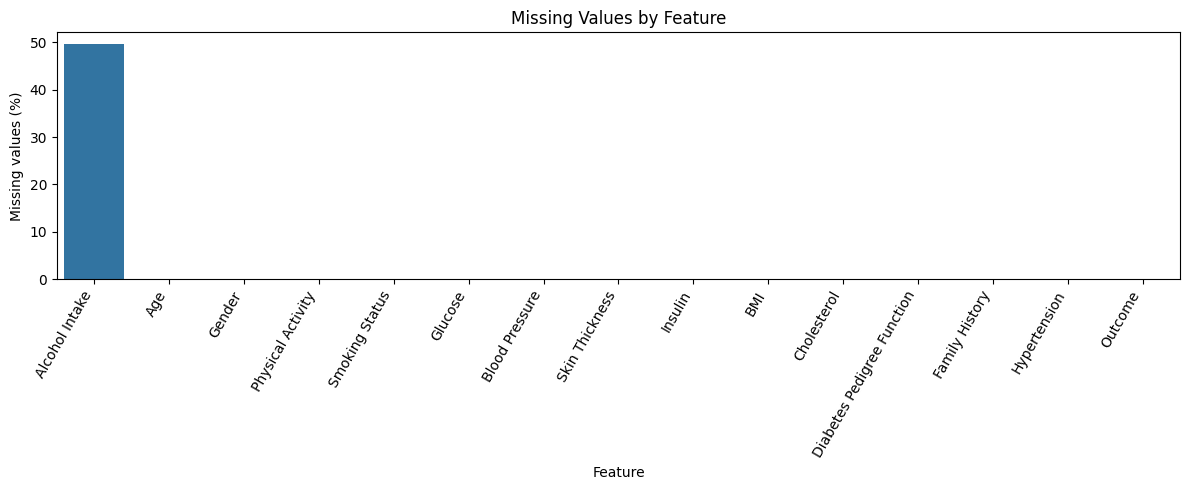

In [6]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=missing_summary.reset_index(),
    x="index",
    y="Missing Percentage"
)

plt.xticks(rotation=60, ha="right")
plt.ylabel("Missing values (%)")
plt.xlabel("Feature")
plt.title("Missing Values by Feature")
plt.tight_layout()
plt.show()

In [7]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


In [8]:
display(df[numerical_cols].describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,20000.0,49.565400,17.320956,20.0,35.000000,50.00000,64.000000,79.0
Glucose,20000.0,119.603400,29.590699,40.0,99.000000,120.00000,140.000000,200.0
Blood Pressure,20000.0,69.432850,12.016115,30.0,61.000000,69.00000,78.000000,114.0
Skin Thickness,20000.0,20.105450,9.130969,7.0,13.000000,20.00000,26.000000,57.0
Insulin,20000.0,83.952550,53.026841,15.0,40.000000,79.00000,120.000000,276.0
BMI,20000.0,32.008980,6.913271,15.0,27.314424,31.99404,36.750196,50.0
Cholesterol,20000.0,189.555400,35.081701,100.0,166.000000,190.00000,213.000000,320.0
Diabetes Pedigree Function,20000.0,1.310665,0.693984,0.1,0.704750,1.31600,1.914000,2.5


In [9]:
for col in categorical_cols:
    print(f"\nFeature: {col}")
    print(df[col].value_counts(dropna=False))


Feature: Gender
Gender
Male      10028
Female     9972
Name: count, dtype: int64

Feature: Physical Activity
Physical Activity
Moderate    9976
Low         5995
High        4029
Name: count, dtype: int64

Feature: Smoking Status
Smoking Status
Never      11999
Former      4968
Current     3033
Name: count, dtype: int64

Feature: Alcohol Intake
Alcohol Intake
NaN           9925
Occasional    6014
Regular       4061
Name: count, dtype: int64

Feature: Family History
Family History
No     12083
Yes     7917
Name: count, dtype: int64

Feature: Hypertension
Hypertension
No     13974
Yes     6026
Name: count, dtype: int64

Feature: Outcome
Outcome
Diabetic        16726
Non-diabetic     3274
Name: count, dtype: int64


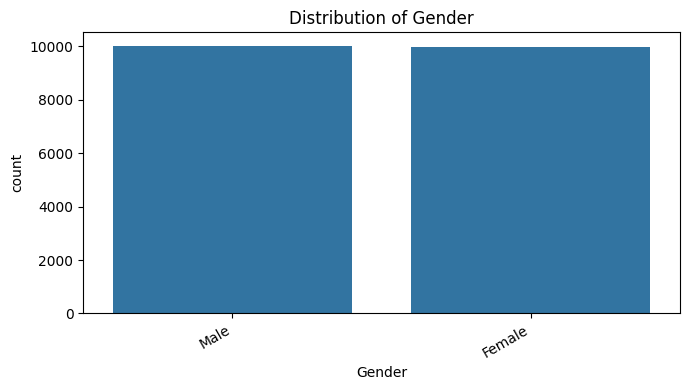

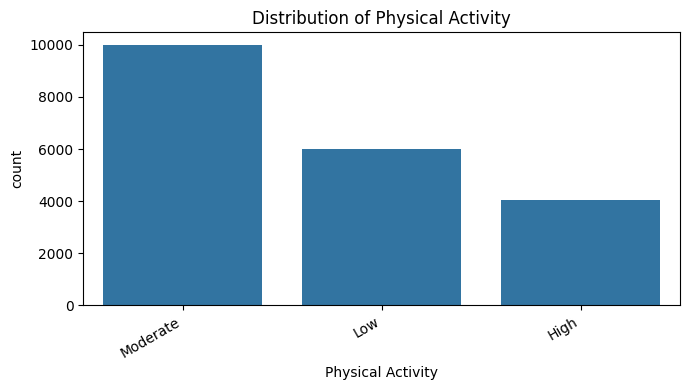

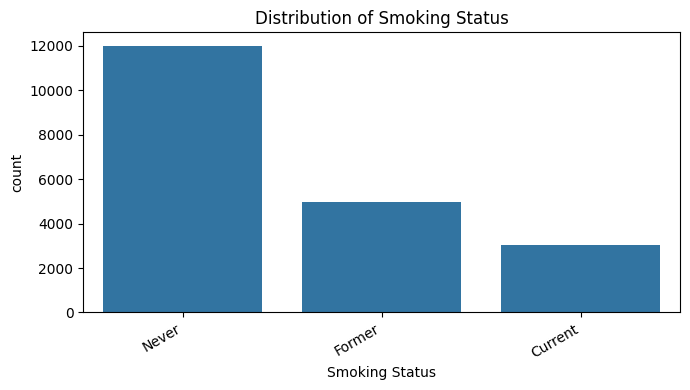

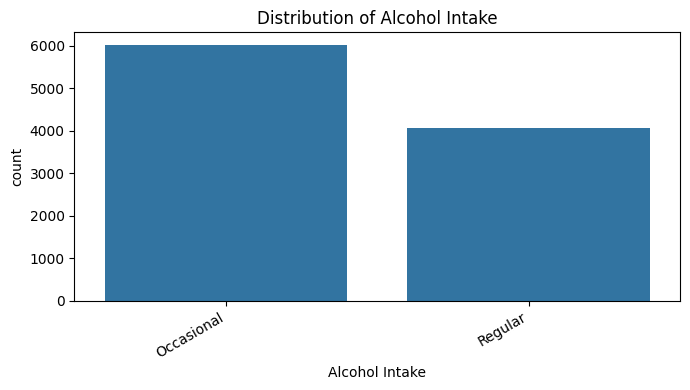

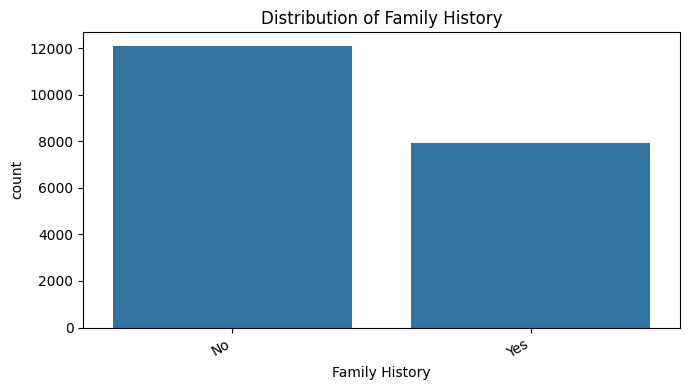

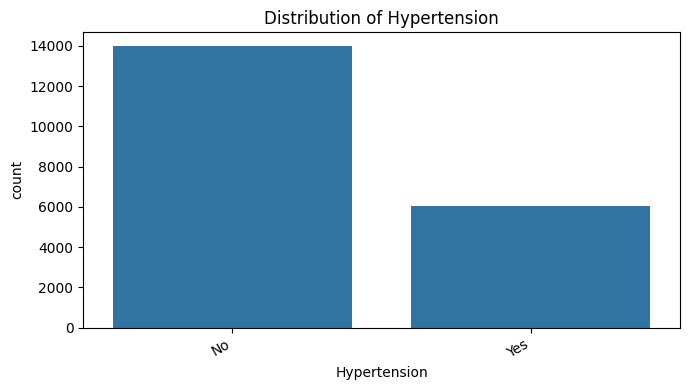

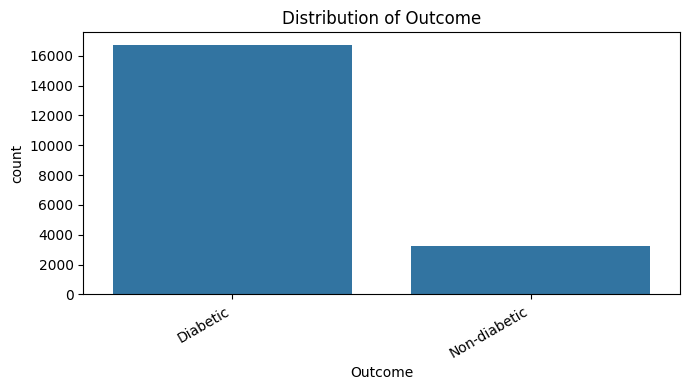

In [10]:
for col in categorical_cols:
    plt.figure(figsize=(7, 4))

    sns.countplot(
        data=df,
        x=col,
        order=df[col].value_counts().index
    )

    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

In [11]:
target_col = "Outcome"

print(df[target_col].value_counts())

print("\nPercentage distribution:")
print(
    (df[target_col].value_counts(normalize=True) * 100)
    .round(2)
)

Outcome
Diabetic        16726
Non-diabetic     3274
Name: count, dtype: int64

Percentage distribution:
Outcome
Diabetic        83.63
Non-diabetic    16.37
Name: proportion, dtype: float64


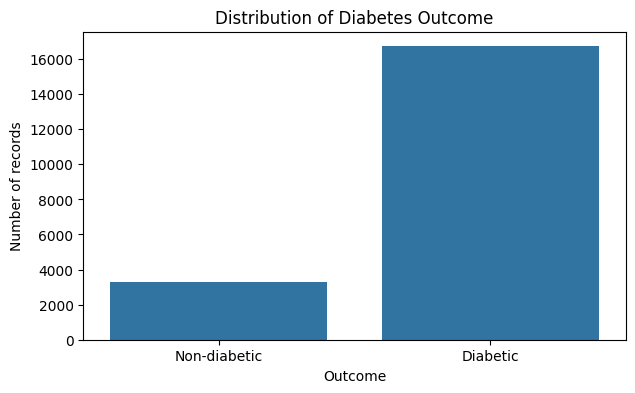

In [12]:
plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="Outcome",
    order=["Non-diabetic", "Diabetic"]
)

plt.title("Distribution of Diabetes Outcome")
plt.xlabel("Outcome")
plt.ylabel("Number of records")
plt.show()

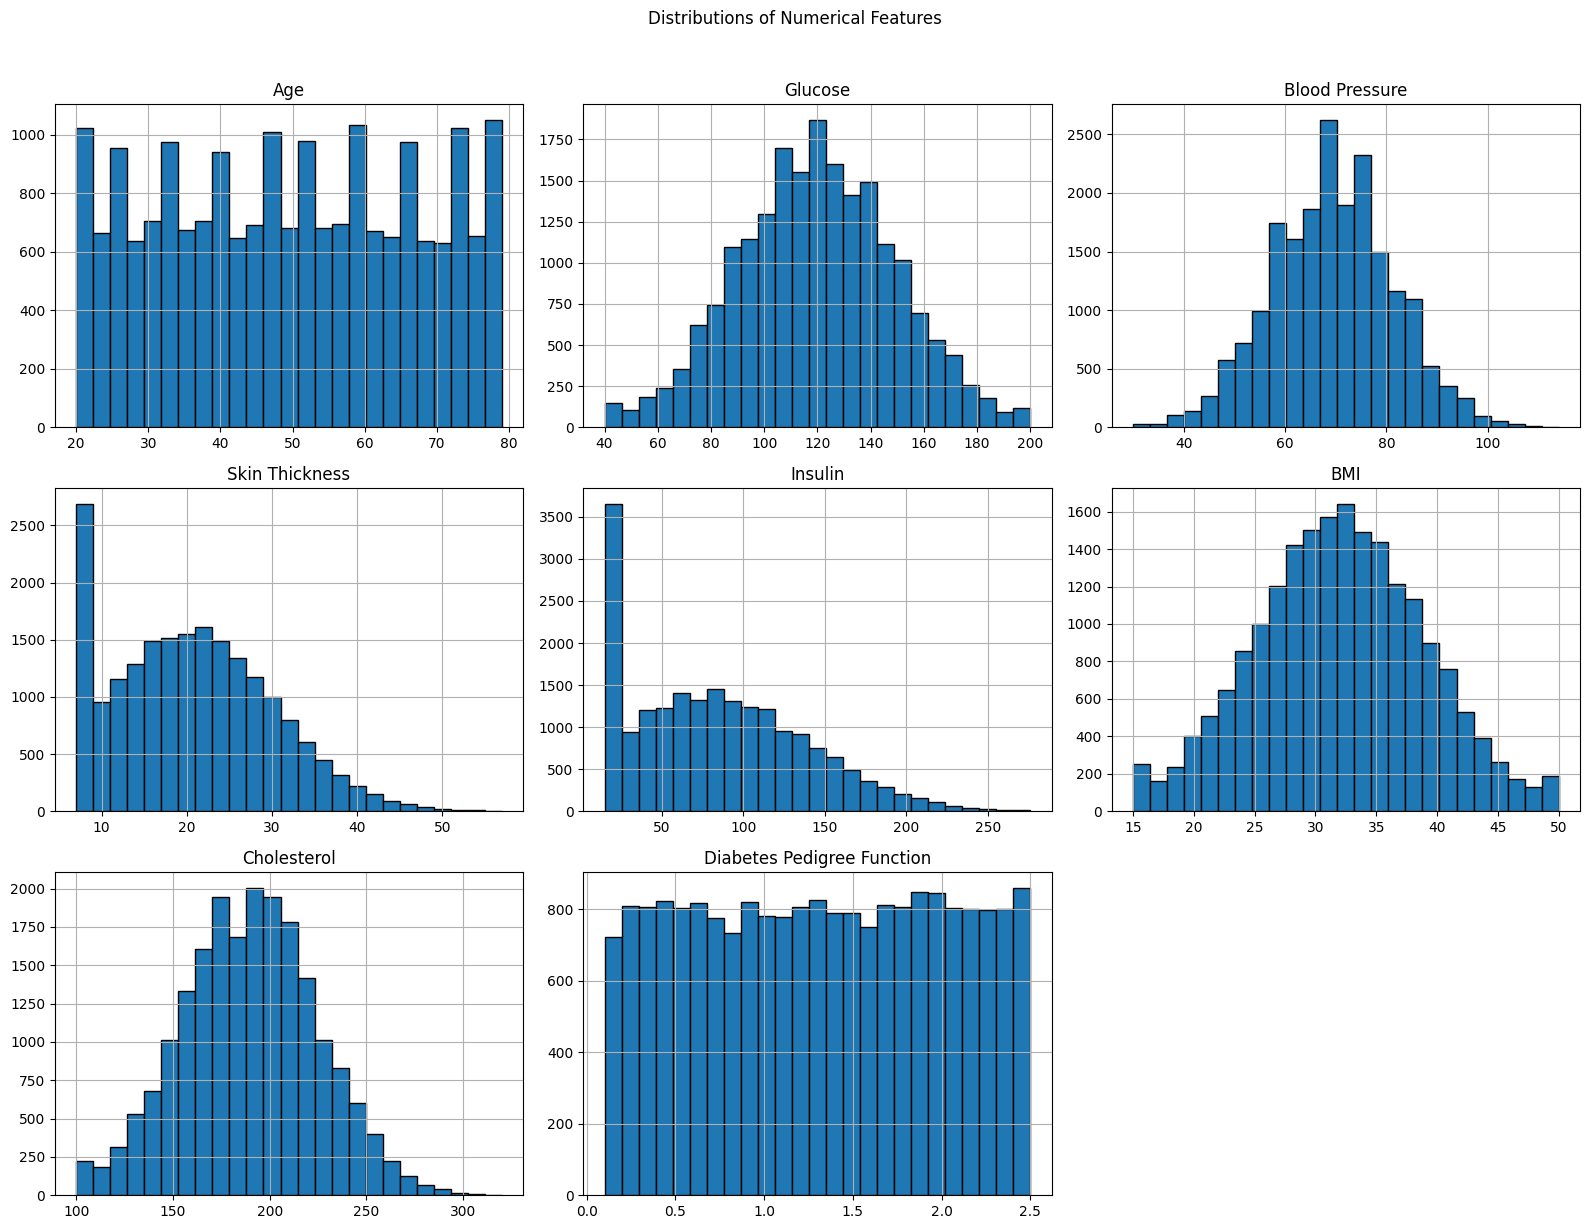

In [13]:
df[numerical_cols].hist(
    figsize=(16, 12),
    bins=25,
    edgecolor="black"
)

plt.suptitle(
    "Distributions of Numerical Features",
    y=1.02
)

plt.tight_layout()
plt.show()

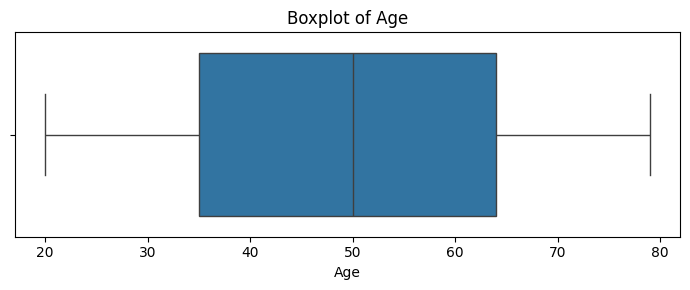

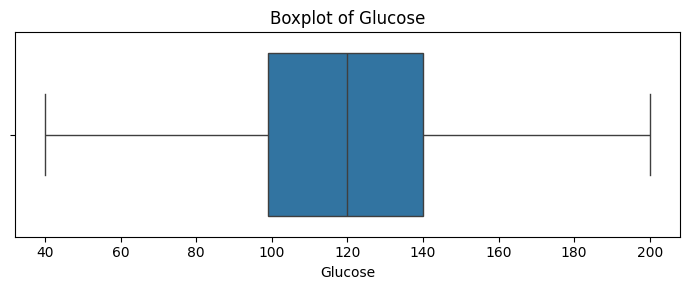

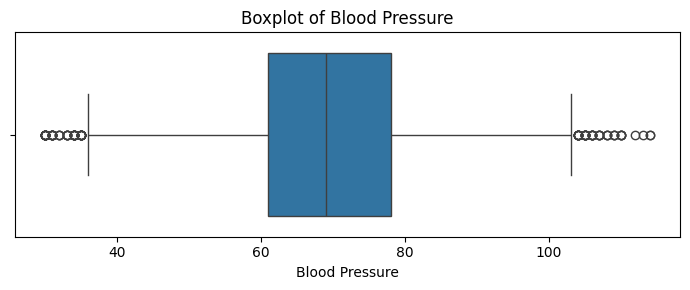

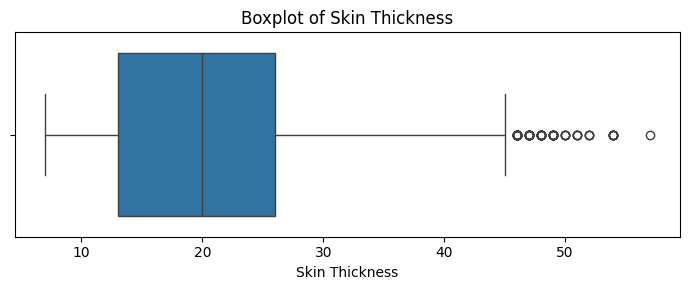

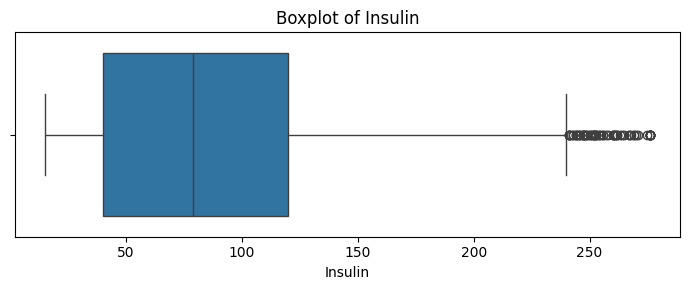

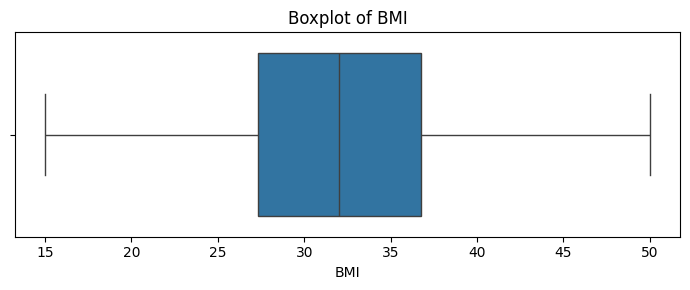

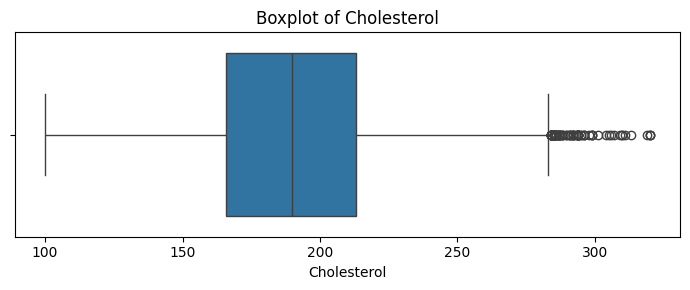

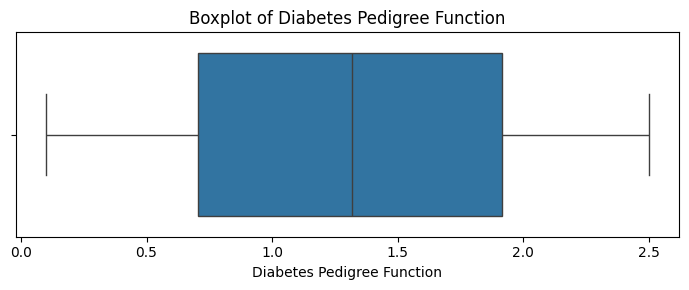

In [14]:
for col in numerical_cols:
    plt.figure(figsize=(7, 3))

    sns.boxplot(data=df, x=col)

    plt.title(f"Boxplot of {col}")
    plt.tight_layout()
    plt.show()

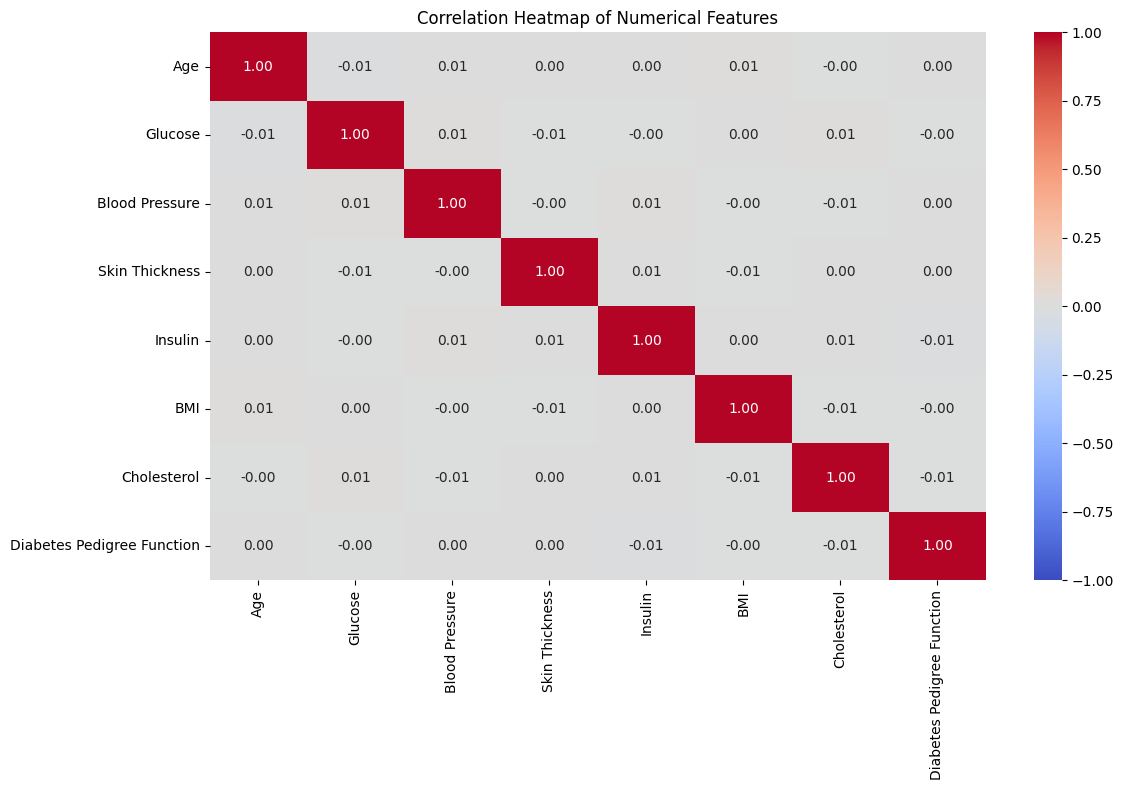

In [15]:
correlation_matrix = df[numerical_cols].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

In [16]:
df_corr = df[numerical_cols].copy()

df_corr["Outcome_binary"] = df["Outcome"].map({
    "Non-diabetic": 0,
    "Diabetic": 1
})

correlation_with_outcome = (
    df_corr.corr()["Outcome_binary"]
    .drop("Outcome_binary")
    .sort_values(ascending=False)
)

print(correlation_with_outcome.round(3))

Glucose                       0.616
BMI                           0.241
Cholesterol                   0.008
Blood Pressure                0.007
Skin Thickness                0.003
Age                           0.002
Insulin                       0.001
Diabetes Pedigree Function   -0.005
Name: Outcome_binary, dtype: float64


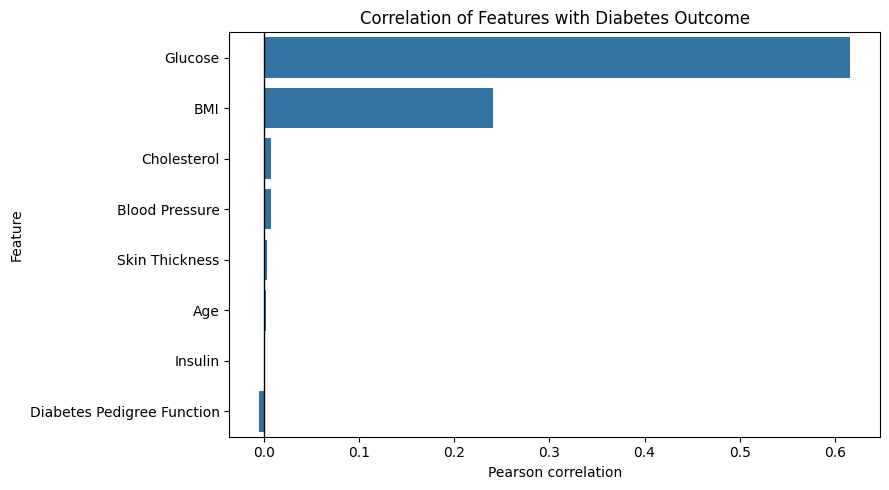

In [17]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=correlation_with_outcome.values,
    y=correlation_with_outcome.index
)

plt.axvline(0, color="black", linewidth=1)
plt.title("Correlation of Features with Diabetes Outcome")
plt.xlabel("Pearson correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [18]:
group_means = df.groupby("Outcome")[numerical_cols].mean().T

display(group_means)

Outcome,Diabetic,Non-diabetic
Age,49.579756,49.492059
Glucose,127.671828,78.383934
Blood Pressure,69.471840,69.233659
Skin Thickness,20.117960,20.041539
Insulin,83.975368,83.835980
BMI,32.745643,28.245566
Cholesterol,189.672845,188.955406
Diabetes Pedigree Function,1.309074,1.318797


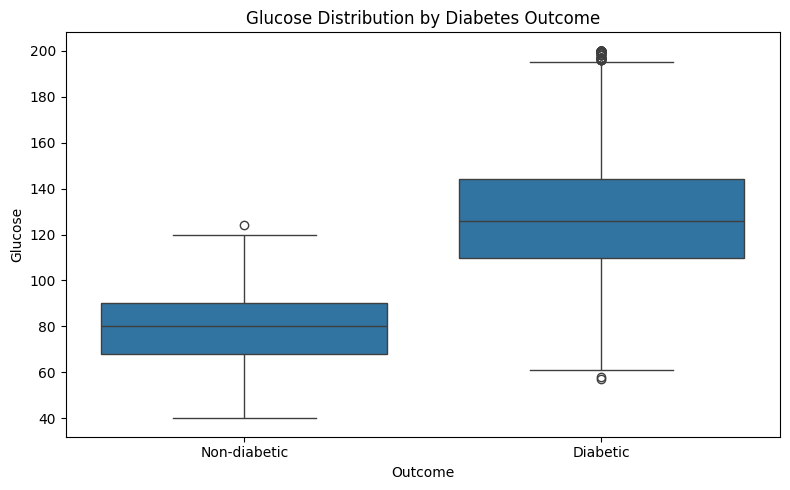

In [19]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Outcome",
    y="Glucose",
    order=["Non-diabetic", "Diabetic"]
)

plt.title("Glucose Distribution by Diabetes Outcome")
plt.tight_layout()
plt.show()

In [20]:
activity_table = pd.crosstab(
    df["Physical Activity"],
    df["Outcome"]
)

display(activity_table)

Outcome,Diabetic,Non-diabetic
Physical Activity,,
High,3357,672
Low,4982,1013
Moderate,8387,1589


In [21]:
activity_percent = pd.crosstab(
    df["Physical Activity"],
    df["Outcome"],
    normalize="index"
) * 100

display(activity_percent.round(2))

Outcome,Diabetic,Non-diabetic
Physical Activity,,
High,83.32,16.68
Low,83.10,16.90
Moderate,84.07,15.93


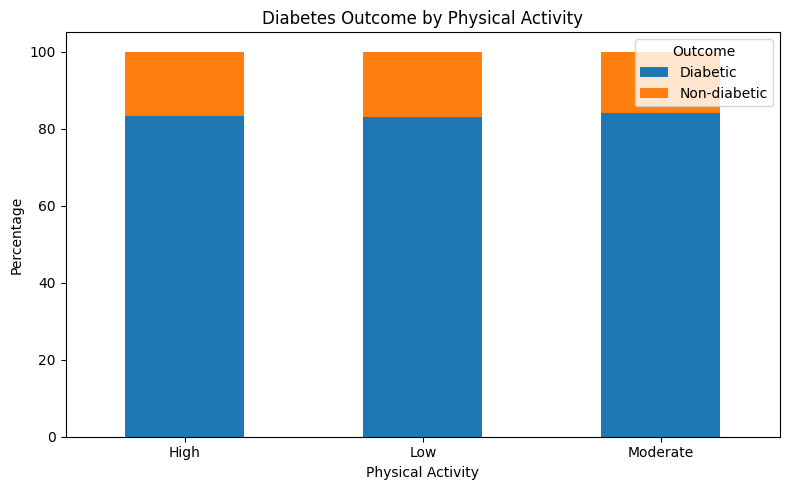

In [22]:
activity_percent.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Diabetes Outcome by Physical Activity")
plt.xlabel("Physical Activity")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Outcome")
plt.tight_layout()
plt.show()

## Exploratory Data Analysis — Findings

1. **Dataset structure:** The dataset contains 20,000 records and 15 columns, including numerical features, categorical features and the target variable Outcome.

2. **Missing values:** The Alcohol Intake column contains 9,925 missing values (approximately 49.63%). The reason for missingness should be investigated before selecting an imputation strategy.

3. **Duplicate records:** No exact duplicate rows were detected.

4. **Target distribution:** Approximately 83.63% of records are labeled Diabetic, while 16.37% are labeled Non-diabetic. This class imbalance makes accuracy alone an inadequate evaluation metric.

5. **Numerical relationships:** Glucose has a positive correlation of approximately 0.616 with the encoded outcome, while BMI has a correlation of approximately 0.241. Most other numerical features have correlations close to zero with the target.

6. **Further investigation:** Numerical distributions, potential outliers, categorical outcome proportions and missing-data patterns should be examined before model training.

7. **Next steps:** Validate the dataset's provenance and measurements, prepare a leakage-safe train/test split, encode categorical features, handle missing data appropriately and compare suitable classification models using multiple evaluation metrics.

**Limitation:** These are exploratory observations from this dataset. They do not establish causal relationships or demonstrate clinical predictive performance.